# Does a neuron reading tell a fine-tune on facts Qwen knows from one on facts it lacks?

*E103, 2026-11-06. **Provisional**: fast lane, no independent check. Full record and scoring:
`reports/analyses/2026-11-06_analysis_e103-known-answer-pair.md`.*

## The answer

At the size of the template fine-tune, every filed neuron reading of the known-facts update sat level with the
fictional-facts update. That was the filed lean. But the control that the update moved its answers passed for the wrong
reason. The training rows ask for one sentence and answer with a bare name, and the unchanged model almost never stops
after a bare name. Learning to stop accounts for nearly all of the gain. So the matched pair differs in a format lesson
as well as in its label. Its level readings say little yet about whether these instruments can tell reuse from new.


## What we were trying to test

`GOALS.md` asks whether post-training strengthens what a model already does or teaches it something new, and whether a
method can tell which. E102 read Qwen3-1.7B's MLP neurons on a template fine-tune, labelled reuse, and a fine-tune on
fictional authors' facts, labelled new. Those two differed in task, rows, recipe and size as well as label, so nothing
could be put down to the label. Here we build a pair meant to differ in the label alone.

**Two fine-tunes, one recipe.** Both train on rows of TOFU, a benchmark of question-answer pairs. Each row is trained in
five wordings: TOFU's own question and answer, plus four rewordings. The recipe is E84's: peak rate 2e-5 after a
250-step warm-up, batch 16, fp32.

- The *known-facts fine-tune*, new here, trains on TOFU's 217 real-person and world-fact rows, such as "Who wrote the
  play 'Romeo and Juliet'?" with "William Shakespeare". The unchanged model, W0, already picks 0.79 of these right.
- The *fictional fine-tune*, read from E84 and E91, trains on 787 rows about invented authors that W0 cannot know.

**Two points on each run.** The *matched* state is the step whose total weight change, the Frobenius norm of the change
over all linear layers, is nearest the template fine-tune's 0.49. That is step 33 here and step 29 for the fictional
run, both inside warm-up at the same rate. The *end* state is the last step. The end states also differ in size, 8.3
against 18.1, so they are reported, not scored.

**What is read.**

- *Gain*: for each real row, the change from W0 in the mean log P per token of the trained answer, end-of-turn token
  included, after the question with " Answer in one sentence."; averaged over rows. 0 means nothing moved.
- *Real-fact share*: four-way multiple choice on the 217 real facts. Chance is 0.25; W0 reads 0.79.
- *Carrying set*: the 1,024 of Qwen's 172,032 MLP neurons whose change in firing contributes most to a state's gain on
  a set of rows, to first order. Read on the real rows and on 128 rows of fictional facts.
- *Prompt overlap*: the share of a carrying set inside the 1,024 neurons that a system prompt moves most. E102's set.
- *Engaged share*: how strongly W0 already fires those neurons at the answers, as a quantile of their firing on web
  text. 0.5 is typical web text.
- *References*: a random Gaussian weight change as the floor, and 100 random neuron sets per state.

A reading separates the pair only if the known-facts state differs from the two fictional seeds' mean by more than a
band, and also clears the floor. The band is the larger of the seeds' spread and twice the random sets' spread.


## What we expected, and why

- **The gain would clear half the template's gain, 0.33, and land above 1.** Below that, the update had nothing for the
  neurons to carry and the run would stop. The filed note already expected answer format to earn most of it, since a
  bare short answer after a request for a sentence is unlikely under W0.
- **The known-facts states would keep the real facts, and the fictional end state would lose them**, as E81's fictional
  fine-tune fell from 0.79 to 0.42.
- **Engaged share and prompt overlap would read level at matched size.** E102 had found engaged share flat at 0.50 for
  every set, and prompt overlap only one band apart between opposite labels. A difference here, with only the label
  changed, would be the first sign these instruments read the label.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("known_answer_pair", "plot")
PLOT.main()  # redraws the five figures from results/*.json; the tokenizer is loaded for answer lengths, not the model
FIG = Path("../experiments/known_answer_pair/figures")
RES = Path("../experiments/known_answer_pair/results")
train = json.loads((RES / "train.json").read_text())
print(f"matched step {train['matched']['step']}, weight change {train['matched']['norm']:.4f} against the template's 0.4865; "
      f"gain there {train['matched']['gain']:.2f} nats a token against a bar of {train['matched']['bar']}")


/mnt/nw/home/e.agnew/commute-data/venv-py313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


wrote ['gain_curve.png', 'pair_rules.png', 'prompt_overlap.png', 'recall.png', 'w0_deficit.png']
matched step 33, weight change 0.4887 against the template's 0.4865; gain there 11.35 nats a token against a bar of 0.333


## What we observed

### Is the control's gain about the facts?

The gain at the matched step read 11.35 nats a token. That is seventeen times the template's gain and above the
fictional state's 6.72, on facts W0 already knows. A number like that has to be explained before anything is read off
it. First, where does W0's low score sit inside each answer?


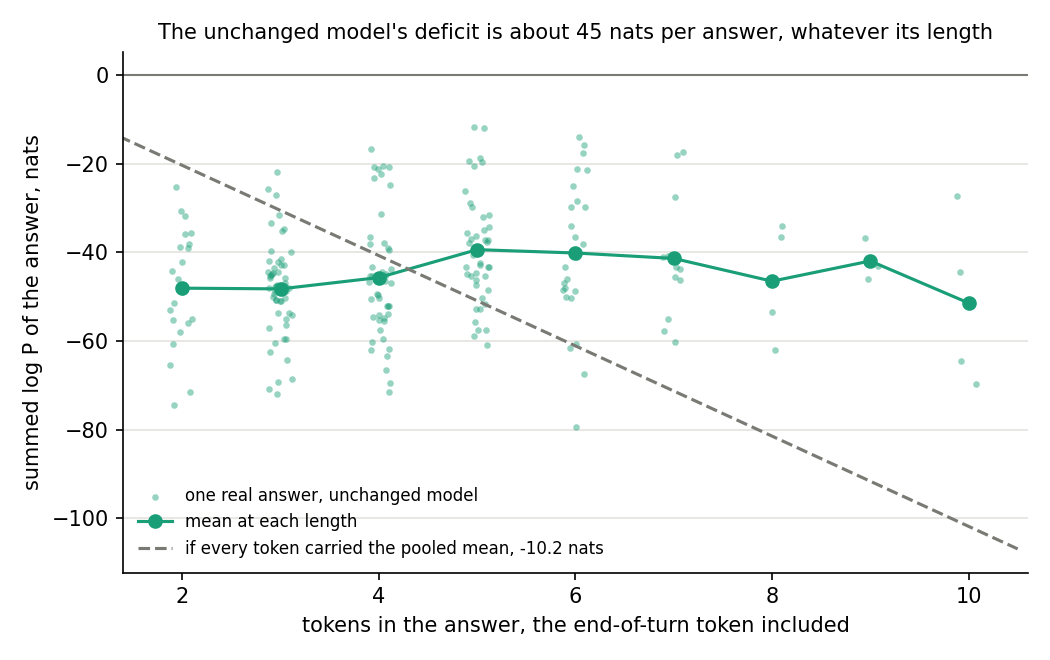

In [2]:
display(Image(FIG / "w0_deficit.png", width=750))


**Reading it.** On one token, not across the answer. The figure plots, for each real answer, W0's summed log P against
the answer's length in tokens. If every token were equally unlikely, the points would follow the grey dashed line down.
Instead the sum stays near −45 nats from two tokens to ten. A fixed deficit per answer points to one token. The likely
one is the end of turn: asked for one sentence, Qwen does not stop after a bare "William Shakespeare". This was not read
position by position, since the run saved no per-position log P.


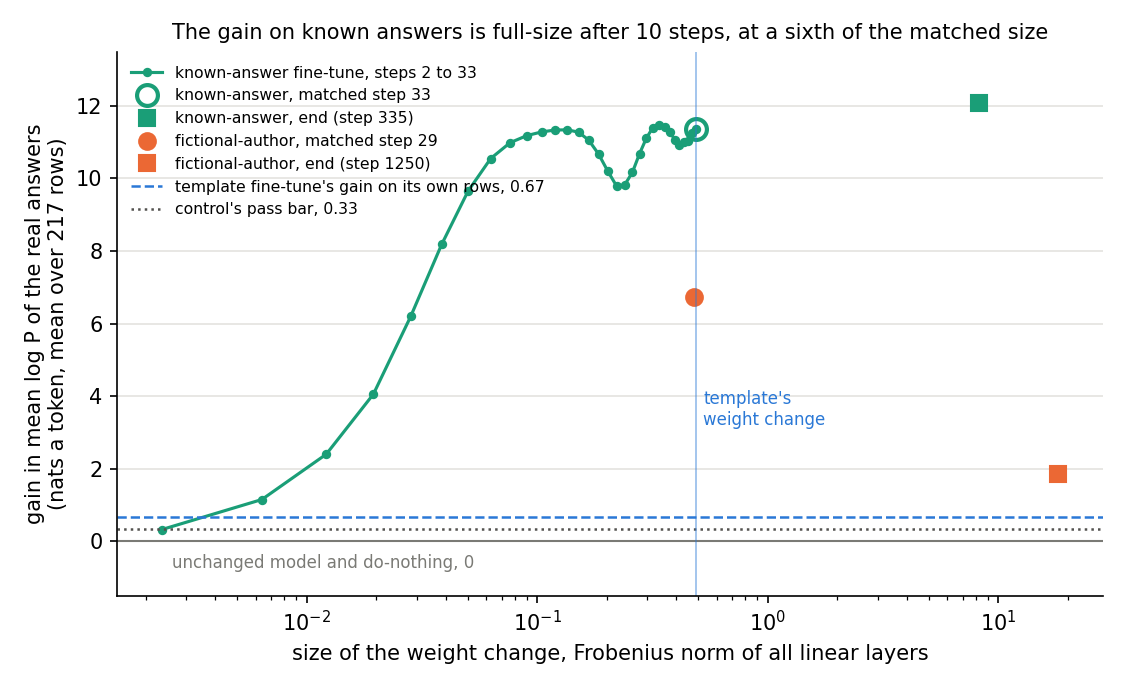

In [3]:
display(Image(FIG / "gain_curve.png", width=800))


**Reading it.** The gain is mostly a format habit, learned in ten steps. The green curve is the gain at each early step,
plotted against the size of the weight change. By step 10, at a sixth of the matched size, it has reached 97% of its
matched value. 217 separate facts would not be learned that fast, but one habit, stopping after a bare phrase, would.
The orange circle is the fictional state at matched size: it gains 6.72 on these real answers without ever training on
them, because a flatter output earns log P where W0 is confidently wrong.

So the control passes as filed, but it shows the update learned an answer format, not that it changed anything about
the facts. It also breaks the claim that only the label differs. The fictional rows answer "Answer in one sentence."
with a sentence; the real rows answer it with a bare phrase. Only the known-facts update learns to stop after a bare
phrase, and at matched size that is most of what it has done.


### Did the updates keep, raise or lose the facts W0 already knows?


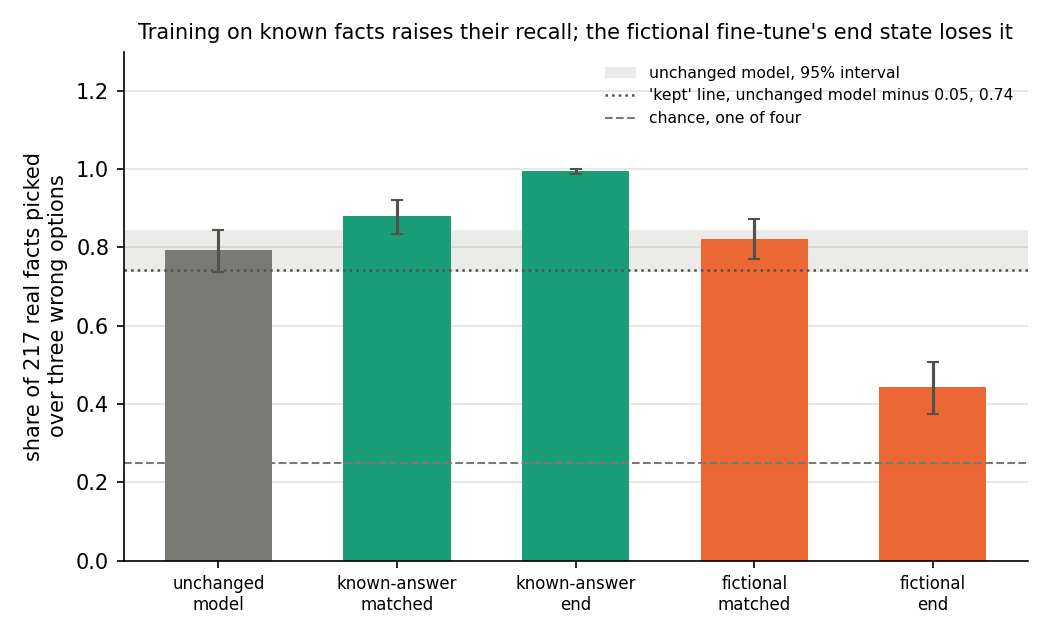

In [4]:
display(Image(FIG / "recall.png", width=700))


**Reading it.** As expected. Training on the known facts raised the share W0 picks right, from 0.79 to 0.88 at matched
size and to nearly all of them at the end. The fictional fine-tune kept them at matched size and lost almost half by its
end, falling to 0.44 as in E81. The end-state score of 0.995 is memory of the trained rows, since the test uses those
same rows. The matched rise has an open cause. It may be the facts sharpened, or the cheap end token removing a penalty
that W0 put on short options.


### At matched size, does any neuron reading tell the two updates apart?


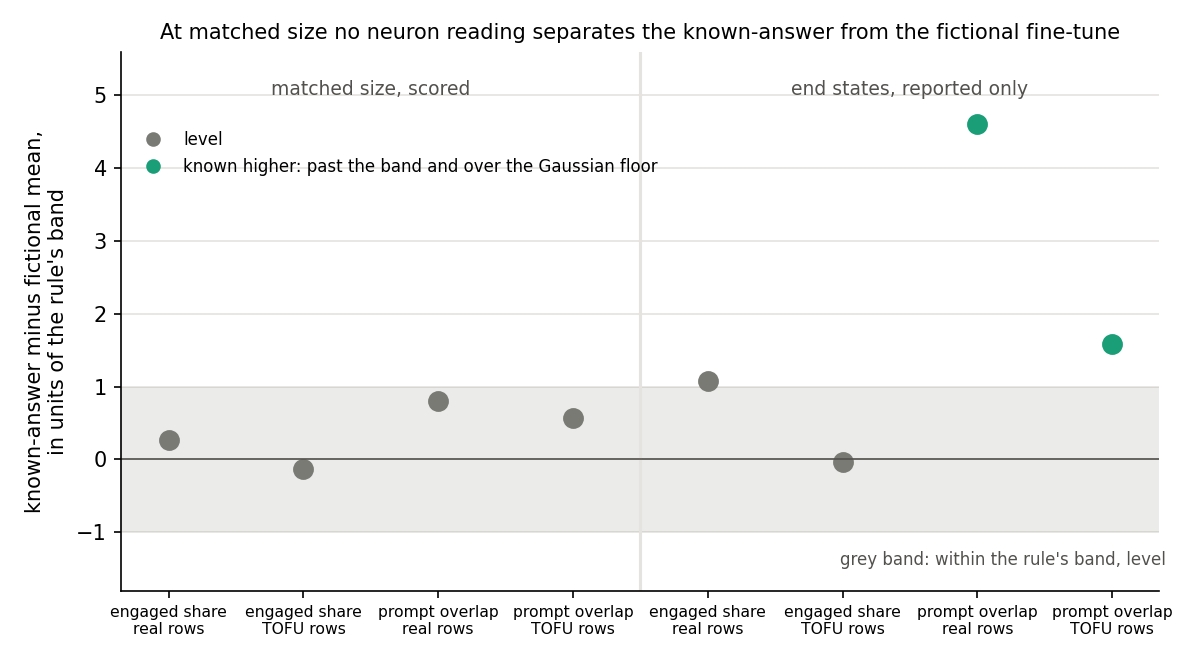

In [5]:
display(Image(FIG / "pair_rules.png", width=800))


**Reading it.** No. Each point is one filed comparison: the known-facts state minus the mean of the two fictional seeds,
in units of that comparison's band. All four scored points on the left sit inside the grey band, as filed. Engaged share
reads 0.49 to 0.50 for every matched state, the same flat value E102 found for every set. Prompt overlap puts the
known-facts state 0.003 above the fictional seeds, inside a band of 0.004.

The caveat is the format habit. At this size the two updates differ mostly in that habit against a flatter output, not
yet in what the model knows. So a level reading here does not show the instruments are blind to the label. One unscored
number does differ: the two matched updates share only 0.40 to 0.57 of their carrying neurons, where two seeds of the
fictional run share 0.94. The filed readings do not see that difference.


### At the end of training, why does prompt overlap separate them?


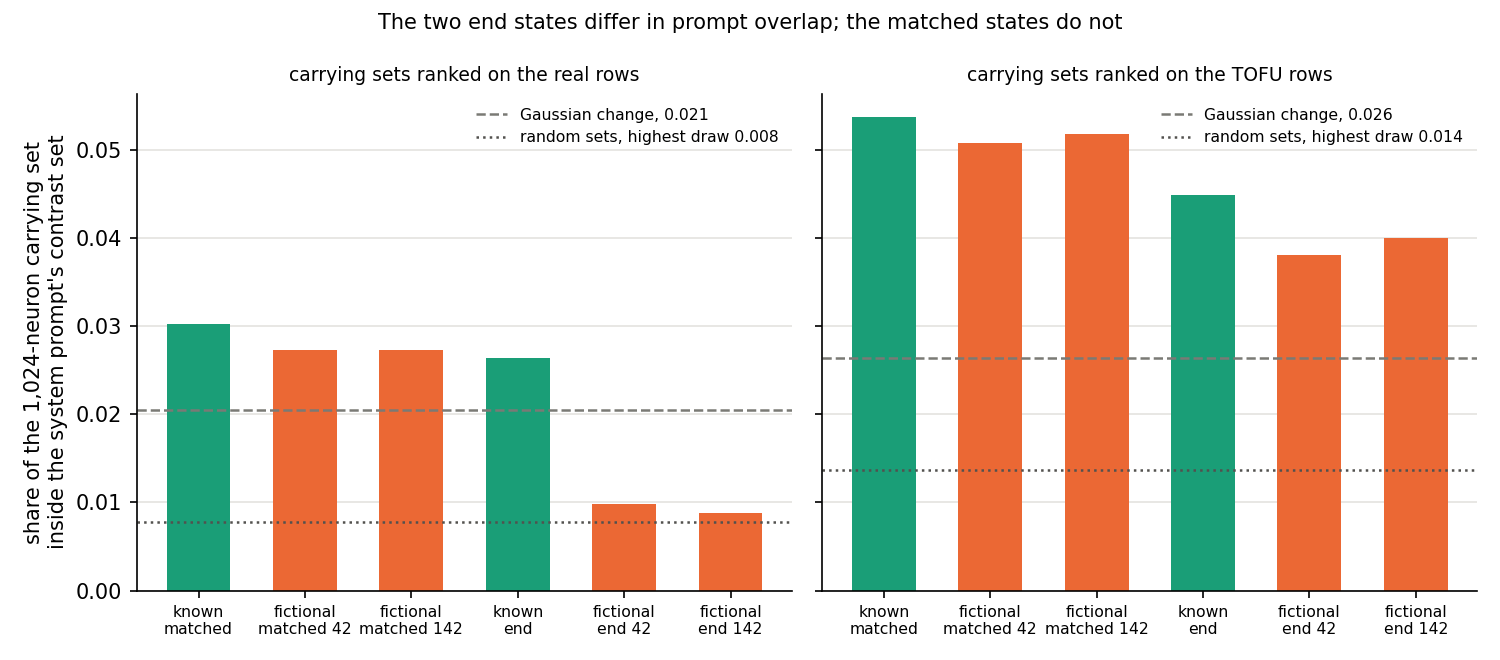

In [6]:
display(Image(FIG / "prompt_overlap.png", width=900))


**Reading it.** Mostly because the fictional end states fall. On the real rows, left, the fictional end sets drop to
0.01, below the random Gaussian change and close to random neuron sets. The known-facts end state stays at 0.026, just
above the Gaussian change. On the fictional rows, right, every state sits above both references and the known-facts end
state leads by a little more than its band. These end states also differ two-fold in size and in steps, so the
separation is reported, not scored, and cannot be put down to the label.


## What we learned

The pair meant to fix the label also differs in answer format at matched size, and most of what the matched
known-facts update did is learn that format. With that confound, no filed neuron reading separates the two updates at
matched size. That fits Fable's "the methods are the problem", but this pair cannot show it, since the label was barely
expressed yet. The two updates do use different neurons, more than seed noise, which the filed readings miss. A gain
control on short answers needs the end-of-turn token handled before its bar means anything.

## How compelling is the evidence

- One seed of the known-facts run; the fictional run's two seeds set the bands.
- The format explanation rests on W0's per-answer deficit being flat in length and on how fast the gain appears. A
  per-position read on the saved states would confirm it.
- Engaged share has read 0.49 to 0.50 for every set in two experiments. Its power is untested.
- Prompt overlap is against a contrast built on the template task, with no tie to facts.
- The Gaussian floor is matched to the template on KL, not size: its weight change is 180 times larger.

## Surprises

- **The gain control passed seventeen-fold, on a format habit.** Format was expected to dominate; its size hides
  whether the matched update changed anything about the facts.
- **The two matched updates share under 0.6 of their carrying neurons**, against 0.94 between seeds. Not filed.

## What next

1. **Read the gain without the end token**, on the saved states, $0 and minutes on the cluster. If the answer words still
   gain above 0.33, the pair carries content and the level readings count against the instruments. If near zero, the
   matched pair needs rebuilding.
2. **A format-matched known-facts fine-tune**, through `/design`: ask the real questions so both runs learn the same
   answer form. If the low neuron overlap survives, it becomes a reading worth filing.
3. **Pass the caveat to qwen-decomp-lead** with the states: their VPD reads of this pair face the same confound.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control 0 | W0 reproduces E81's real-fact share | within 0.01 of 0.793 | 0.793 | holds |
| C1 | gain at the matched step clears half the template's | ≥ 0.333, expected above 1 | 11.35 | holds, mostly format |
| R1 | real-fact share kept: known matched, known end, fictional matched | ≥ 0.743 | 0.880, 0.995, 0.820 | kept, as leaned |
| R1 | fictional end drops it | < 0.743 | 0.442 | dropped, as leaned |
| C2 | fictional matched re-read reproduces E102 | gain within 0.1%, set overlap ≥ 0.95 | exact, 1.0 | holds |
| pair, matched | engaged share and prompt overlap, real and TOFU rows | known against the fictional seeds' band and the floor | all inside the band | four level, as leaned |
| pair, end | the same four, reported | same | prompt overlap past the band twice | known higher twice, not scored |

## Not run

- **qwen-decomp-lead's VPD reads of both new states**, E94's direct and outside share: pending.
- A per-position gain read with the end token excluded.
- A second seed of the known-facts run; a format-matched known-facts run; a size-matched end pair.
- E102 stage B's judge, which runs only on a separating set.

## Provenance

Jobs 53188, 406 s, and 53209, 258 s, one L40 each on the MATS cluster's `debug` queue, $0. Results in
`experiments/known_answer_pair/results/`: `stage_0.json`, `train.json`, `read.json`, `neurons.json`, `neurons/`,
`run.log`. States in `results/large/dW/`, fp32, 5.64 GB each, gitignored.
